In [ ]:


import numpy as np








import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

In [2]:
from config import *


In [3]:
def get_trajectory(graph,popsize,d,r,repeat_num,timestep=10):
    output_name = f"CC-N-{popsize}-geom-{graph}-d-{d}-r-{r}-tr-{timestep}-repeat-{repeat_num}"
    loc_2 = f"{results_loc}{output_name}.txt"
    nas = []
    try:
        with open(loc_2, 'r') as f:
            lines = f.readlines()
    except FileNotFoundError:
        print(f"File not found: {loc_2}")
        return None

    nas = []
    for line in lines:
            if line.strip() and line[:len("Na ")]=="Na ":
                nas.append(float(line.split(' ')[1]))
    return nas

def get_extinction_times(graph,popsize,d,r,timestep=10,time_relax=10):
    extinction_times = []
    for repeat_num in range(1000):
        nas = get_trajectory(graph,popsize,d,r,repeat_num,timestep)
        # print(nas)
        if nas is not None and len(nas) >= time_relax and len(nas)<timestop:
            time =0
            for i in nas:
                if i>0:
                    time+=1/i
            extinction_times.append(time)
    return np.array(extinction_times)
                
    


In [4]:
time_relax = 10
d=0.5
r=1
pop_size=30
extinction_times = get_extinction_times("M", pop_size, d, r, time_relax=time_relax, timestep=0.001)
print(len(extinction_times))

979


0.0009331679951987455


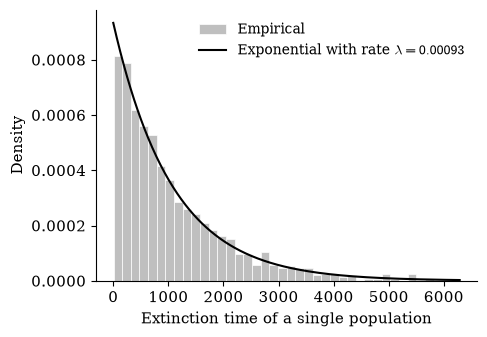

In [5]:

lambda_hat = 1 / np.mean(extinction_times)
print(lambda_hat)

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "mathtext.fontset": "cm",
})

fig, ax = plt.subplots(figsize=(5, 3.5))

ax.hist(extinction_times, bins=40, density=True, color="0.75",
        edgecolor="white", linewidth=0.5, label="Empirical")

x = np.linspace(0, max(extinction_times), 500)
pdf = lambda_hat * np.exp(-lambda_hat * x)
ax.plot(x, pdf, color="black", linewidth=1.5,
        label=rf"Exponential with rate $\lambda = {lambda_hat:.5f}$")

ax.set_xlabel("Extinction time of a single population")
ax.set_ylabel("Density")
ax.legend(frameon=False, loc="upper right", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
fig.savefig("extinction_times_fit.pdf")  # vector format for the paper
plt.show()